# Radiation Profiles & Pfotzer Peak Estimation

> Map continuous atmospheric radiation curves to precisely locate the Pfotzer-Regener maximum and generate standardized profiles for cross-flight comparison.

**Current outputs are SYNTHETIC software verification, not HERA measurements or HERA model results.** The original flight event/log files were not in the attachments. This notebook opens the completed example and can run the same pipeline on verified real inputs once they are supplied.

The project uses only XGBoost for new predictive modeling. It evaluates reconstructed CPS-altitude profiles and defensible peak locations, not just row-level R2. See `docs/DATA_REQUIREMENTS.md` for the exact six raw files needed.

## 1. Choose a run

Extract the complete project ZIP before opening this notebook. Install the requirements as described in README.md. The default reads the included completed example without retraining. Set `RUN_TRAINING=True` for a new reproducible experiment. Output folders are unique so old evidence is retained.

For real data, change `MODE` to `real_hera`, point `DATA_PATH` and `METADATA_PATH` at a verified combined table and its metadata, then enable training. Do not bypass the unit/clock/exposure checks.

In [2]:
from pathlib import Path
import sys, json

# If needed, set PROJECT_ROOT manually to the extracted project folder.
PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd().parent,
    Path('/content/Radiation_Profiles_Pfotzer_Peak_Estimation')]
    if (p / 'pfotzer_xgb').is_dir()), None)
assert PROJECT_ROOT is not None, 'Extract the whole project and set PROJECT_ROOT.'
sys.path.insert(0, str(PROJECT_ROOT))

MODE = 'synthetic'  # or 'real_hera' after verified measurements are available
RUN_TRAINING = False
CONFIG_PATH = PROJECT_ROOT / 'config' / ('demo.json' if MODE == 'synthetic' else 'research.json')
DATA_PATH = PROJECT_ROOT / ('data/synthetic/synthetic_flights.csv' if MODE == 'synthetic'
                            else 'data/processed/run01/combined.csv')
METADATA_PATH = None if MODE == 'synthetic' else PROJECT_ROOT / 'data/processed/run01/verified_metadata.json'
RESULTS = PROJECT_ROOT / ('results/synthetic_demo' if MODE == 'synthetic' else 'results/hera_run01')
CONFIG = json.loads(CONFIG_PATH.read_text())
print('DATA MODE:', MODE)
print('Seeds:', CONFIG['seeds'])
print('Variants:', CONFIG['variants'])
if MODE == 'synthetic':
    print('All examples below are synthetic. Real HERA training remains pending.')

DATA MODE: synthetic
Seeds: [11, 42, 73]
Variants: ['baseline', 'engineered', 'tuned_engineered', 'altitude_only', 'pressure_only', 'altitude_pressure']
All examples below are synthetic. Real HERA training remains pending.


In [3]:
from datetime import datetime, timezone
from pfotzer_xgb.experiments import run

if RUN_TRAINING:
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    RESULTS = PROJECT_ROOT / 'results' / f'{MODE}_{stamp}'
    run(DATA_PATH, RESULTS, CONFIG, METADATA_PATH)
assert (RESULTS / 'provenance.json').is_file(), 'No completed run: supply verified data and enable training.'
print('Loaded completed run:', RESULTS.name)

Loaded completed run: synthetic_demo


## 2. Check data quality first

Review exclusions, units, missing sensors, synchronization and coverage before interpreting scores. A rate is counts divided by verified live time, not automatically flux or dose. Empty or shutdown intervals must not silently become zero-rate observations.

,flight_id,input_rows,valid_rows,excluded_rows,altitude_min_m,altitude_max_m,largest_time_gap_s,zero_count_rows,counts_and_exposure_available,gps_zero_pair_rows
0,SYNTHETIC_A,1557,1557,0,500.0,28500.0,5.0,0,True,0
1,SYNTHETIC_B,1473,1473,0,500.0,27000.0,5.0,0,True,0
2,SYNTHETIC_C,612,612,0,500.0,11500.0,5.0,0,True,0


Excluded rows: 0


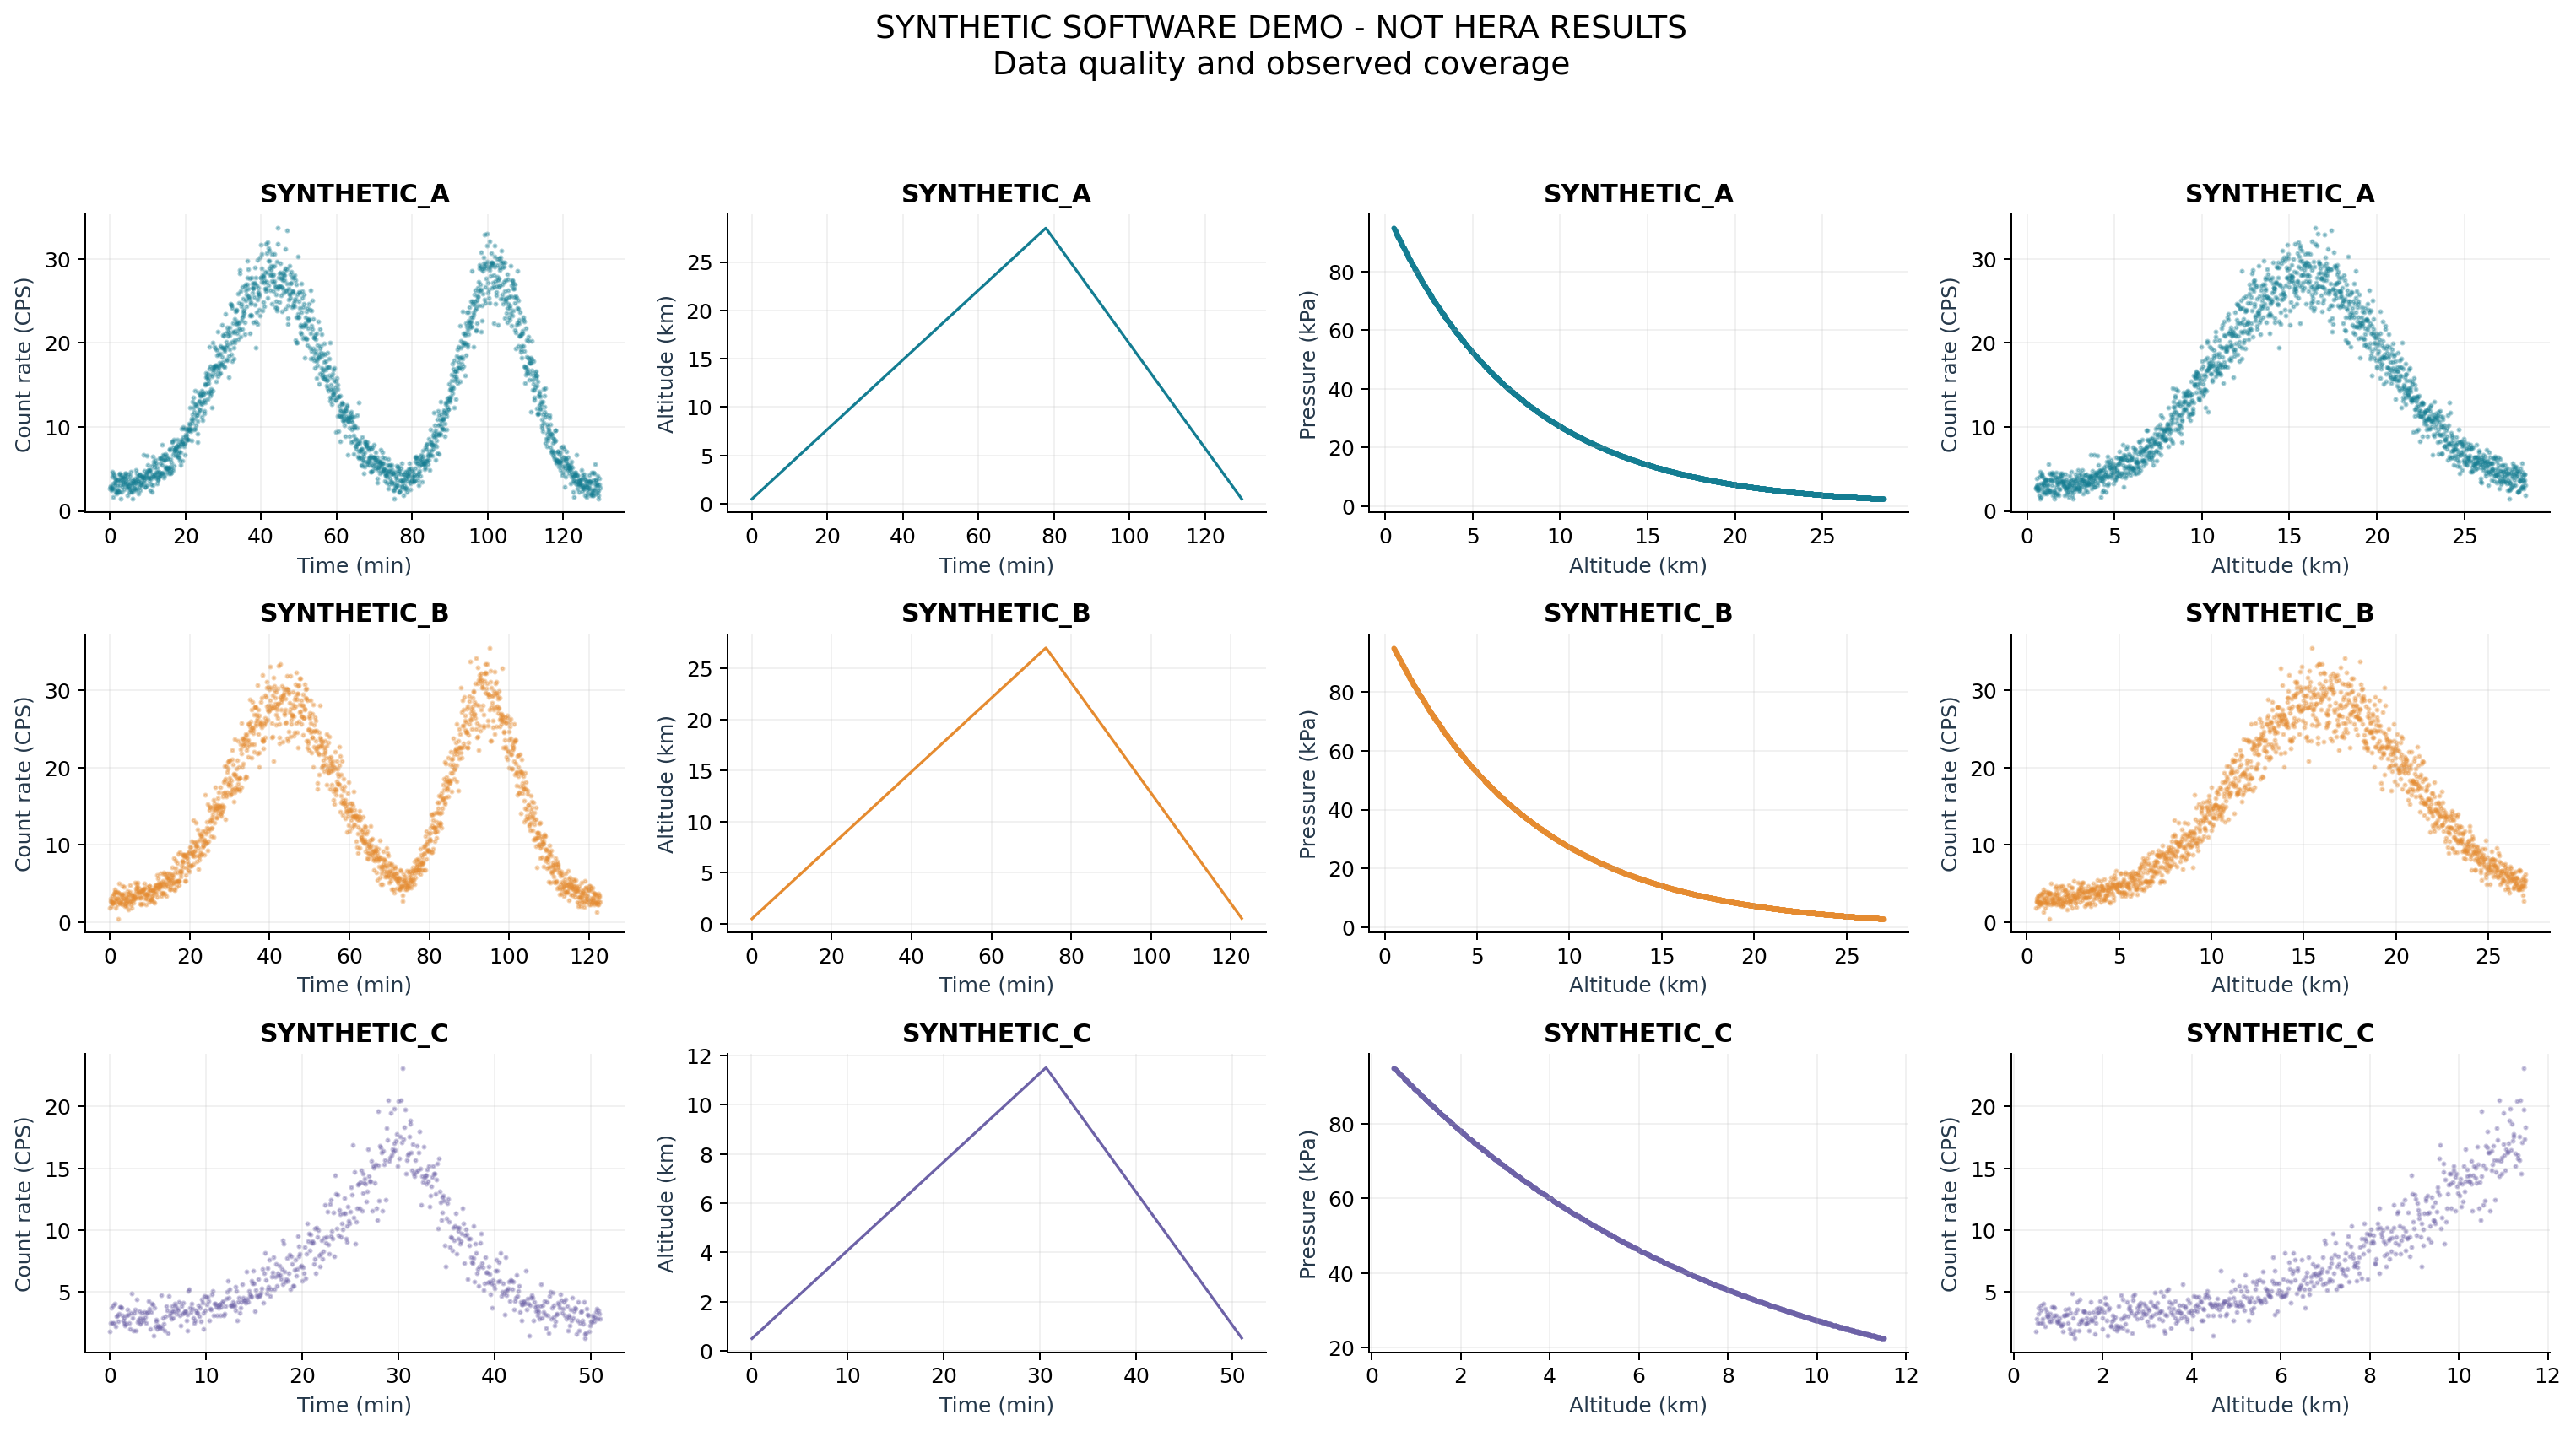

In [4]:
import pandas as pd
from IPython.display import display, Image, Markdown
quality = pd.read_csv(RESULTS / 'quality_reports/flight_quality.csv')
excluded = pd.read_csv(RESULTS / 'quality_reports/excluded_rows.csv')
display(quality)
print('Excluded rows:', len(excluded))
display(Image(filename=str(RESULTS / 'figures/data_quality.png'), width=1200))

## 3. Inspect the measured reference profiles

Ascent and descent use the same fixed 250 m altitude grid, but are evaluated separately. Counts and exposure are summed within bins where available. Unsupported bins remain gaps. The reported `identified` status is a screened candidate requiring physical and detector review; it is not proof by itself of the Pfotzer-Regener maximum.

The third synthetic flight was deliberately stopped before its generating peak. It should be edge-limited and have no accepted peak altitude.

In [6]:
observed_peaks = pd.read_csv(RESULTS / 'peak_tables/measured_peaks.csv')
display(observed_peaks[['flight_id', 'phase', 'status', 'peak_altitude_m', 'peak_cps', 'reason']])
if MODE == 'synthetic':
    incomplete = observed_peaks[observed_peaks.flight_id == 'SYNTHETIC_C']
    assert (incomplete.status == 'edge_limited').all()
    assert incomplete.peak_altitude_m.isna().all()

,flight_id,phase,status,peak_altitude_m,peak_cps,reason
0,SYNTHETIC_A,ascent,identified,15625.0,28.415131,interior_prominent_bracketed_candidate
1,SYNTHETIC_A,descent,identified,16875.0,29.060980,interior_prominent_bracketed_candidate
2,SYNTHETIC_B,ascent,identified,15875.0,28.407768,interior_prominent_bracketed_candidate
3,SYNTHETIC_B,descent,identified,16125.0,30.178595,interior_prominent_bracketed_candidate
4,SYNTHETIC_C,ascent,edge_limited,NaN,NaN,maximum_touches_coverage_boundary
5,SYNTHETIC_C,descent,edge_limited,NaN,NaN,maximum_touches_coverage_boundary


## 4. Validate complete flights, then compare XGBoost variants

The outer loop withholds one physical flight. The inner loop tunes only on the other flights; the outer target never selects hyperparameters, early stopping or features. Seeds 11, 42 and 73 are all reported. There are three independent flights, not nine independent experiments.

The baseline is the original seven sensor inputs. Engineered features add log pressure, a dry-air density proxy and flight derivatives. Diagnostic variants use altitude, pressure or both. Any feature/tuning gains must show up on withheld flights. A high score within a single flight is not the main test.

,variant,rmse_cps_mean,rmse_cps_std,mae_cps_mean,r2_mean,independent_flights
0,altitude_only,1.785995,0.290531,1.340446,0.936069,3
1,altitude_pressure,1.768982,0.285211,1.327270,0.937189,3
2,baseline,1.793354,0.357592,1.352045,0.937189,3
3,engineered,1.849783,0.320688,1.405499,0.931196,3
4,pressure_only,1.757654,0.282040,1.319948,0.937930,3
5,tuned_engineered,1.829127,0.354207,1.385840,0.934051,3


,variant,flight_id,rmse_cps_mean,rmse_cps_std,rmse_cps_min,rmse_cps_max,mae_cps_mean,mae_cps_std,mae_cps_min,mae_cps_max,r2_mean,r2_std,r2_min,r2_max
6,baseline,SYNTHETIC_A,1.887891,0.000099,1.887784,1.887980,1.444463,0.001006,1.443487,1.445497,0.955196,0.000005,0.955192,0.955201
7,baseline,SYNTHETIC_B,2.094179,0.030049,2.065772,2.125636,1.556077,0.018986,1.537918,1.575793,0.947597,0.001505,0.946018,0.949016
8,baseline,SYNTHETIC_C,1.397992,0.003164,1.394548,1.400768,1.055594,0.005293,1.049807,1.060191,0.908774,0.000413,0.908412,0.909224
15,tuned_engineered,SYNTHETIC_A,1.896708,0.011527,1.885840,1.908797,1.451094,0.011828,1.437819,1.460511,0.954775,0.000550,0.954198,0.955293
16,tuned_engineered,SYNTHETIC_B,2.144675,0.011160,2.133074,2.155335,1.593733,0.009834,1.586276,1.604878,0.945046,0.000572,0.944499,0.945639
17,tuned_engineered,SYNTHETIC_C,1.445999,0.047198,1.412605,1.499995,1.112693,0.044215,1.083468,1.163560,0.902332,0.006426,0.894977,0.906858


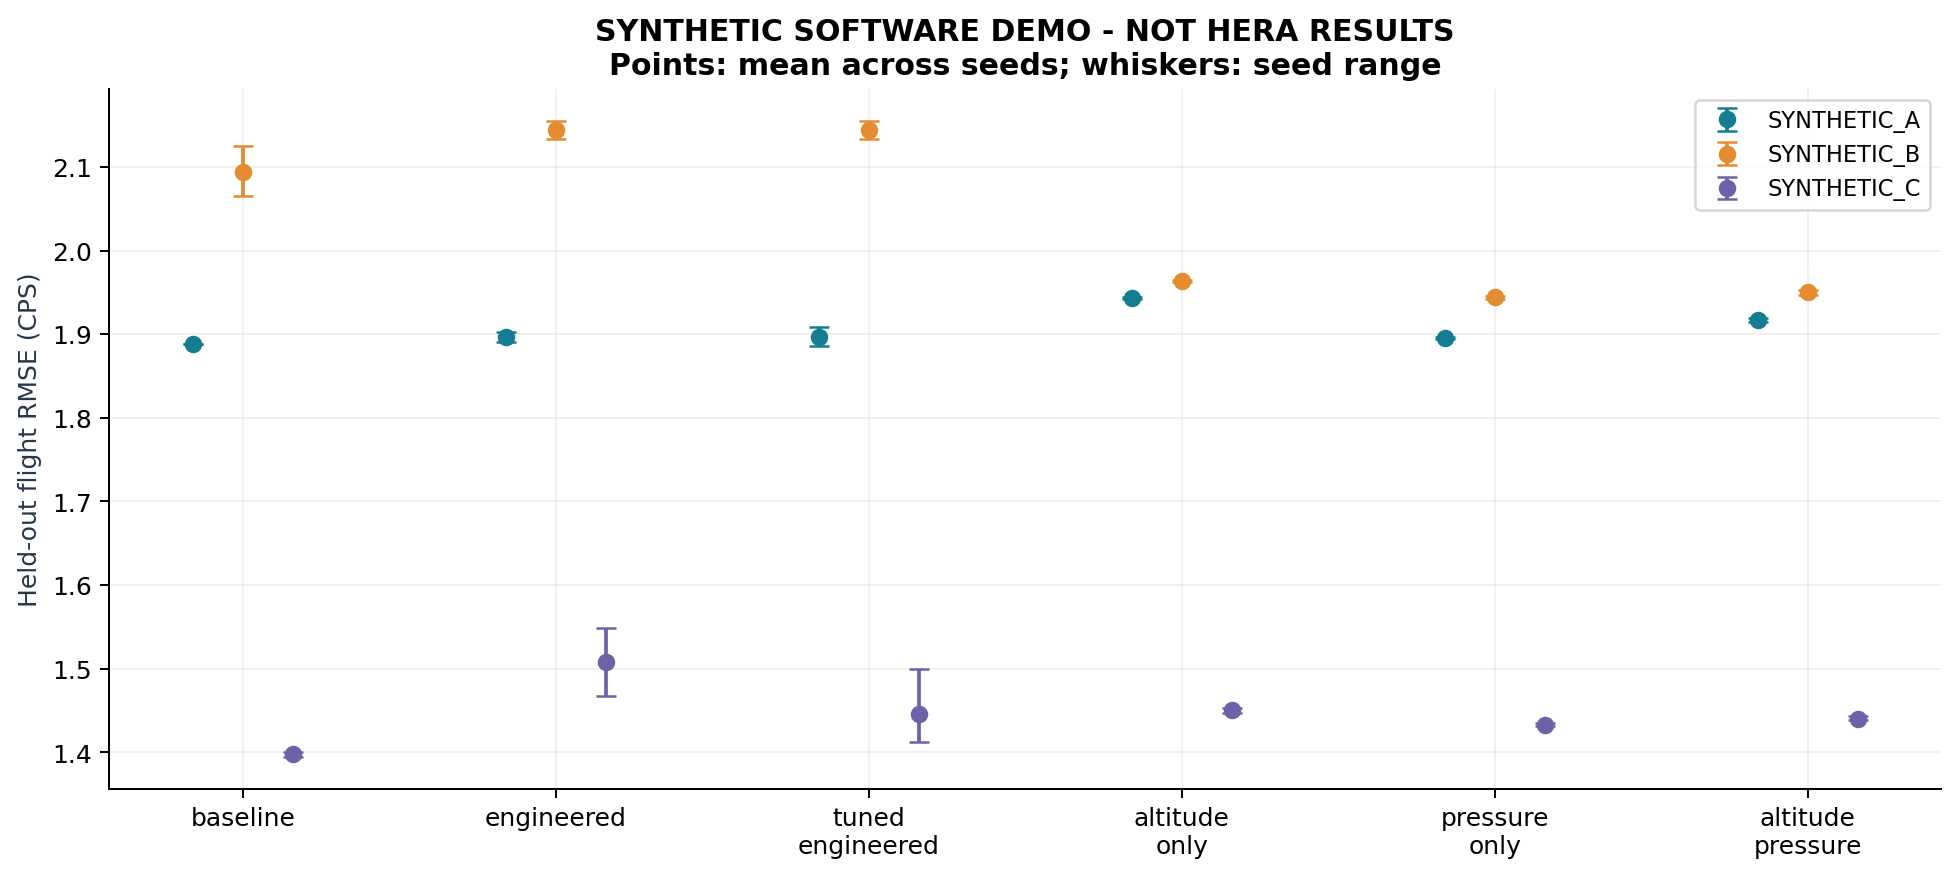

In [7]:
summary = pd.read_csv(RESULTS / 'cv_metrics/summary_across_flights.csv')
display(summary[['variant', 'rmse_cps_mean', 'rmse_cps_std', 'mae_cps_mean', 'r2_mean', 'independent_flights']])
seeds = pd.read_csv(RESULTS / 'cv_metrics/seed_variability.csv')
display(seeds[seeds.variant.isin(['baseline', 'tuned_engineered'])])
display(Image(filename=str(RESULTS / 'figures/xgboost_variants.png'), width=1050))

In [6]:
splits = pd.read_csv(RESULTS / 'cv_metrics/split_audit.csv')
search = pd.read_csv(RESULTS / 'cv_metrics/hyperparameter_search.csv')
for _, row in splits.iterrows():
    assert row.flight_id not in row.train_flights.split('|')
for _, row in search.iterrows():
    assert row.outer_flight not in row.inner_train_flights.split('|')
    assert row.inner_validation_flight not in row.inner_train_flights.split('|')
    assert row.inner_validation_flight != row.outer_flight
print('Outer fits:', len(splits), '| inner search fits:', len(search))
display(search[search.selected].drop_duplicates(['outer_flight', 'seed'])[
    ['outer_flight', 'seed', 'candidate', 'mean_inner_flight_rmse_cps', 'params_json']])

Outer fits: 54 | inner search fits: 126


,outer_flight,seed,candidate,mean_inner_flight_rmse_cps,params_json
2,SYNTHETIC_A,11,1,3.970286,"{""colsample_bytree"": 0.75, ""gamma"": 0, ""learni..."
14,SYNTHETIC_A,42,0,3.969636,"{""colsample_bytree"": 0.9, ""gamma"": 0, ""learnin..."
30,SYNTHETIC_A,73,1,3.961349,"{""colsample_bytree"": 0.75, ""gamma"": 0, ""learni..."
42,SYNTHETIC_B,11,0,4.384774,"{""colsample_bytree"": 0.9, ""gamma"": 0, ""learnin..."
56,SYNTHETIC_B,42,0,4.385955,"{""colsample_bytree"": 0.9, ""gamma"": 0, ""learnin..."
70,SYNTHETIC_B,73,0,4.375994,"{""colsample_bytree"": 0.9, ""gamma"": 0, ""learnin..."
94,SYNTHETIC_C,11,5,1.892679,"{""colsample_bytree"": 0.75, ""gamma"": 0.1, ""lear..."
108,SYNTHETIC_C,42,5,1.901175,"{""colsample_bytree"": 0.75, ""gamma"": 0.1, ""lear..."
122,SYNTHETIC_C,73,5,1.903898,"{""colsample_bytree"": 0.75, ""gamma"": 0.1, ""lear..."


## 5. Evaluate reconstructed profiles and peaks together

The predictions use the held-out flight's observed environmental trajectory. They are never built by independently changing altitude while holding physically inconsistent pressure or temperature fixed. The figure shows the mean across the three seed fits and their range; the seed range is **not** a confidence interval.

A peak-altitude difference is reported only when both measured and predicted profiles pass the same structural coverage/prominence screening. Errors on accepted pairs must be read alongside the acceptance fraction.

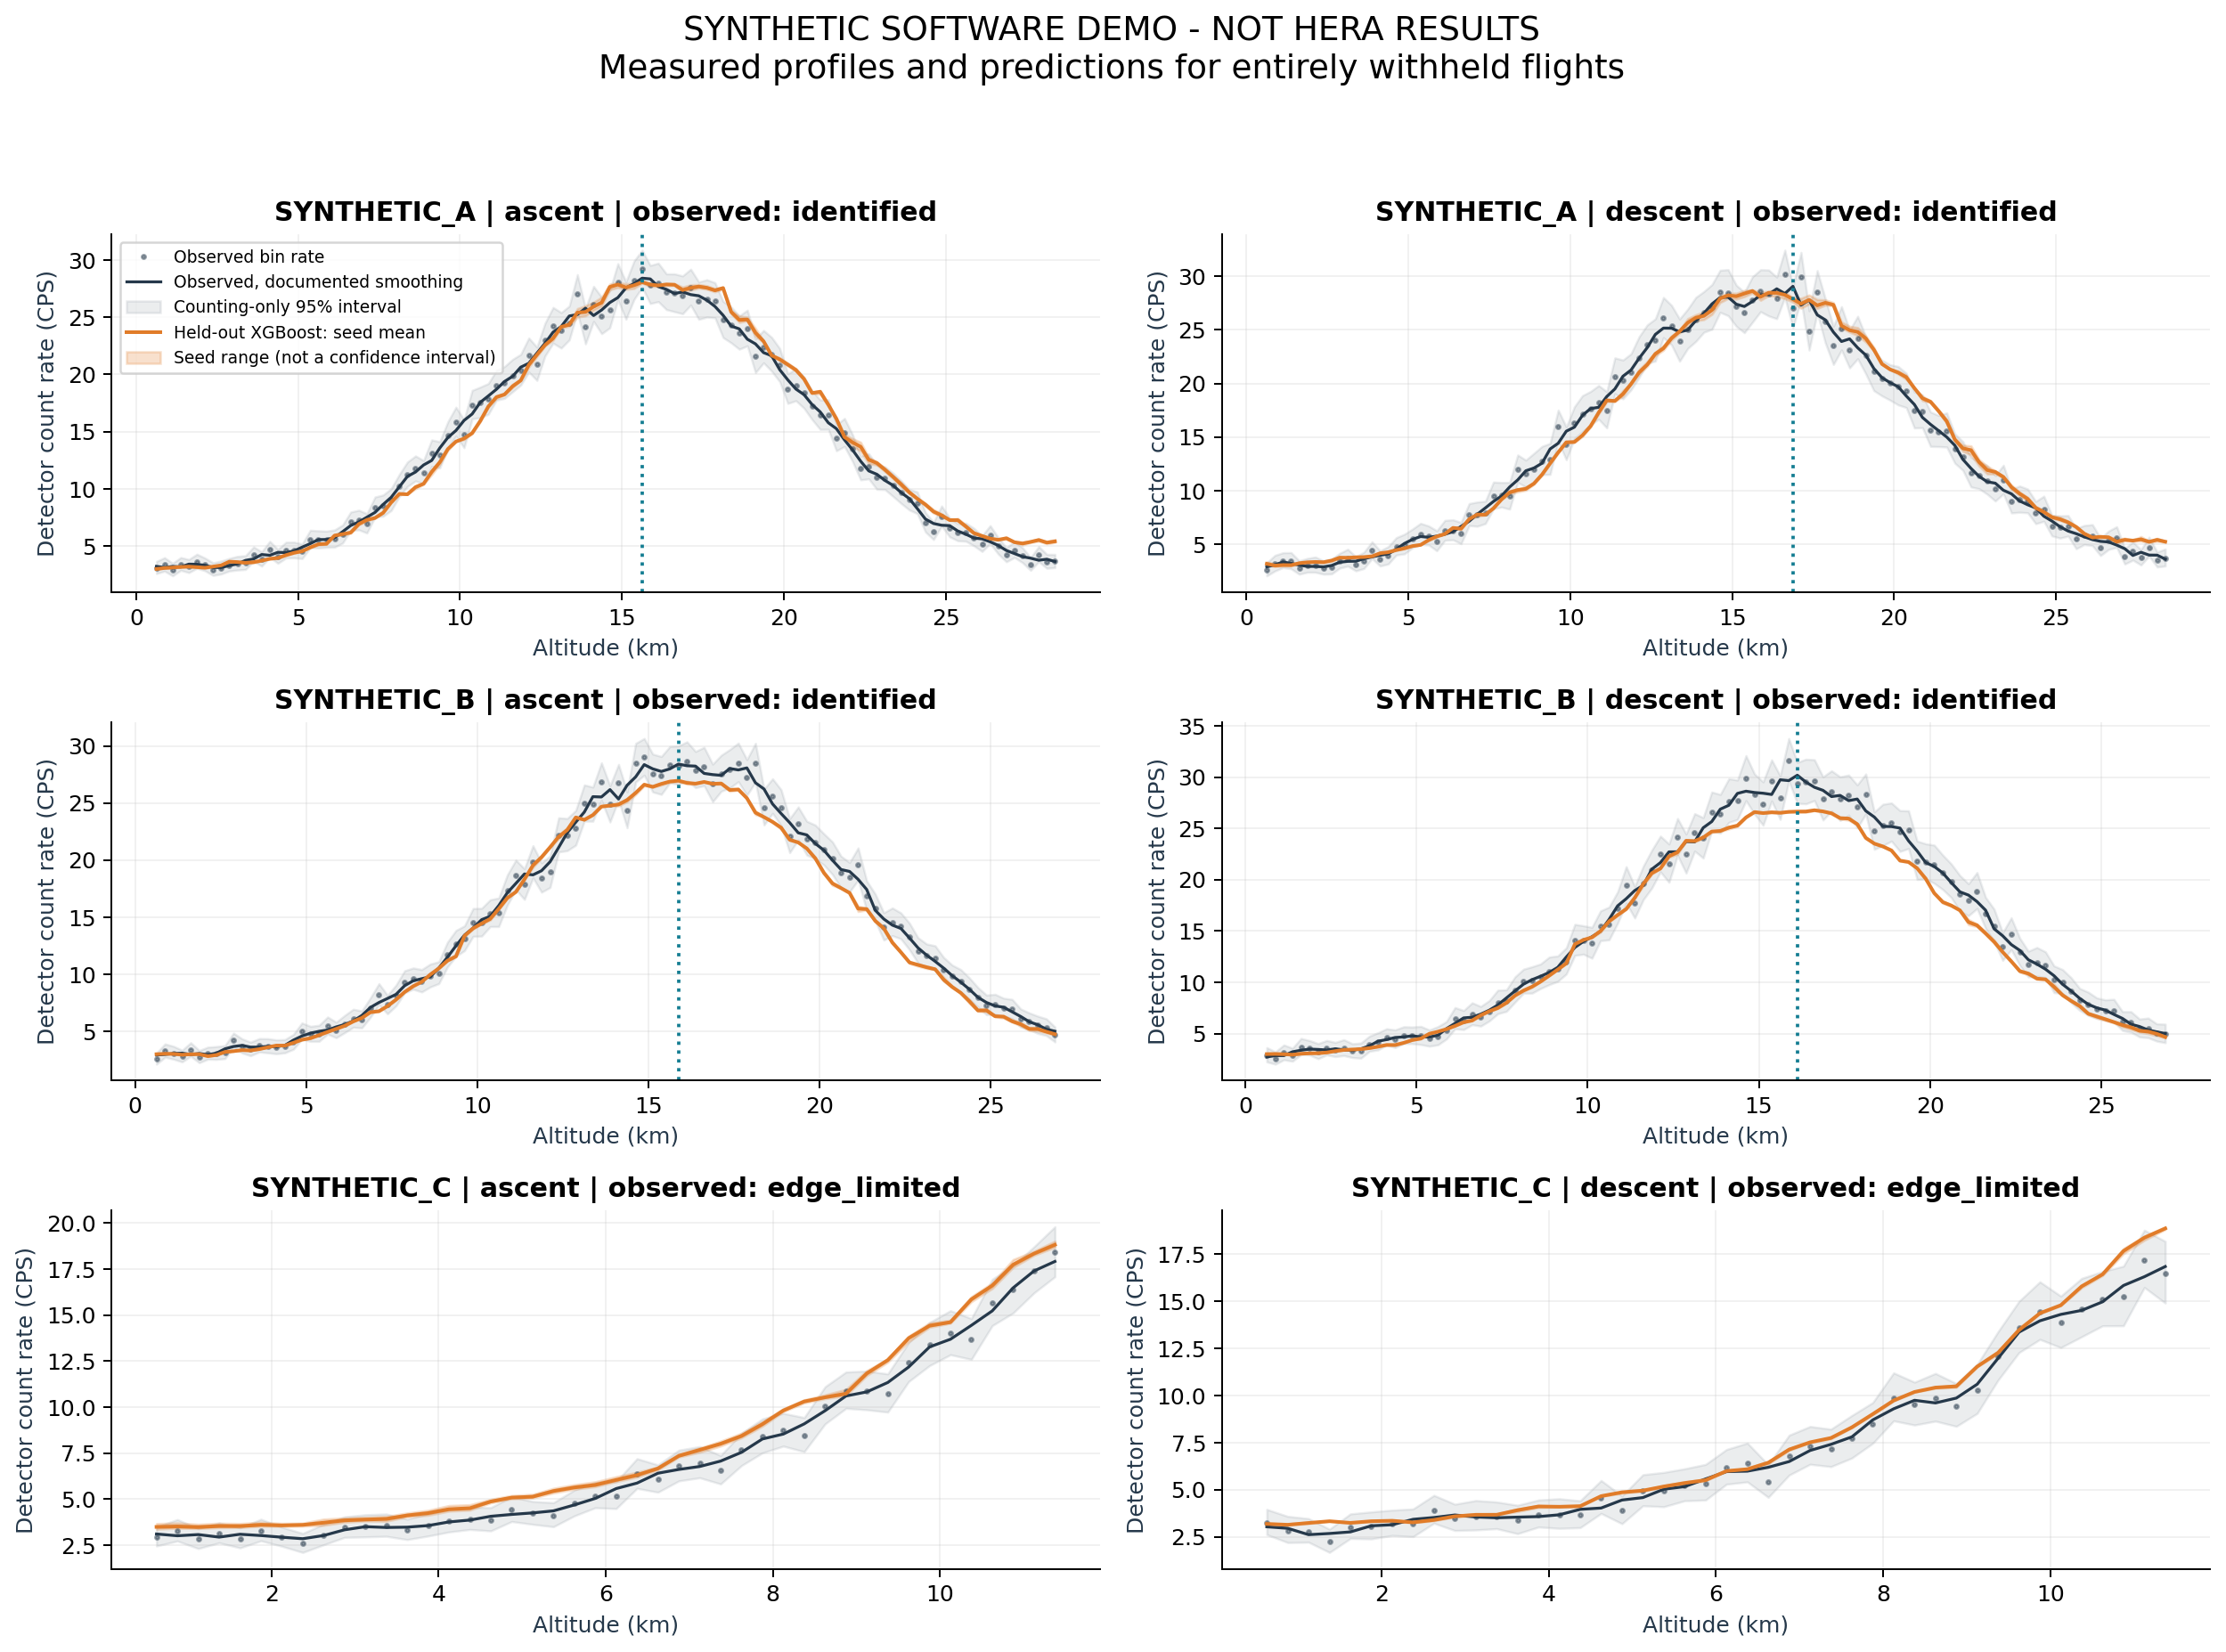

,flight_id,phase,seed,measured_status,predicted_status,measured_peak_m,predicted_peak_m,abs_peak_error_m,profile_rmse_cps
4,SYNTHETIC_A,ascent,11,identified,identified,15625.0,15625.0,0.0,1.035464
5,SYNTHETIC_A,descent,11,identified,identified,16875.0,16375.0,500.0,1.251498
16,SYNTHETIC_A,ascent,42,identified,identified,15625.0,15625.0,0.0,1.061647
17,SYNTHETIC_A,descent,42,identified,identified,16875.0,16375.0,500.0,1.249737
28,SYNTHETIC_A,ascent,73,identified,identified,15625.0,15875.0,250.0,0.992215
29,SYNTHETIC_A,descent,73,identified,identified,16875.0,15375.0,1500.0,1.207720
40,SYNTHETIC_B,ascent,11,identified,identified,15875.0,15875.0,0.0,1.239353
41,SYNTHETIC_B,descent,11,identified,identified,16125.0,16625.0,500.0,1.570484
52,SYNTHETIC_B,ascent,42,identified,identified,15875.0,15875.0,0.0,1.207316
53,SYNTHETIC_B,descent,42,identified,identified,16125.0,16375.0,250.0,1.543877


In [8]:
display(Image(filename=str(RESULTS / 'figures/heldout_profiles.png'), width=1200))
peaks = pd.read_csv(RESULTS / 'peak_tables/heldout_peaks_and_profile_metrics.csv')
display(peaks[peaks.variant == 'tuned_engineered'][['flight_id', 'phase', 'seed',
    'measured_status', 'predicted_status', 'measured_peak_m', 'predicted_peak_m',
    'abs_peak_error_m', 'profile_rmse_cps']])
assert peaks.loc[~peaks.both_identified, 'abs_peak_error_m'].isna().all()

## 6. Check binning and smoothing sensitivity

The following results span 100, 250 and 500 m bins and 1/3-bin smoothing. Small bins may fail minimum sampling and become unresolved. The ranges describe these processing choices; they are not calibrated statistical confidence intervals. All settings are retained rather than selecting a setting to match the held-out target.

In [9]:
sensitivity = pd.read_csv(RESULTS / 'peak_tables/measured_sensitivity.csv')
display(sensitivity[['flight_id', 'phase', 'bin_m', 'smoothing_bins', 'status', 'peak_altitude_m', 'reason']])
identified = sensitivity[sensitivity.status == 'identified']
display(identified.groupby(['flight_id', 'phase']).peak_altitude_m.agg(['count', 'min', 'max']).rename(
    columns={'count': 'identified_settings', 'min': 'sensitivity_min_m', 'max': 'sensitivity_max_m'}))

,flight_id,phase,bin_m,smoothing_bins,status,peak_altitude_m,reason
0,SYNTHETIC_A,ascent,100.0,1,ambiguous,NaN,competing_prominent_maxima
1,SYNTHETIC_A,ascent,100.0,3,identified,15550.0,interior_prominent_bracketed_candidate
2,SYNTHETIC_A,ascent,250.0,1,identified,15625.0,interior_prominent_bracketed_candidate
3,SYNTHETIC_A,ascent,250.0,3,identified,15625.0,interior_prominent_bracketed_candidate
4,SYNTHETIC_A,ascent,500.0,1,identified,15750.0,interior_prominent_bracketed_candidate
5,SYNTHETIC_A,ascent,500.0,3,identified,15750.0,interior_prominent_bracketed_candidate
6,SYNTHETIC_A,descent,100.0,1,unresolved,NaN,gap_in_supported_altitude_coverage
7,SYNTHETIC_A,descent,100.0,3,unresolved,NaN,gap_in_supported_altitude_coverage
8,SYNTHETIC_A,descent,250.0,1,identified,16625.0,interior_prominent_bracketed_candidate
9,SYNTHETIC_A,descent,250.0,3,identified,16875.0,interior_prominent_bracketed_candidate


identified_settings  sensitivity_min_m  sensitivity_max_m
flight_id   phase                                                             
SYNTHETIC_A ascent                     5            15550.0            15750.0
            descent                    4            14750.0            16875.0
SYNTHETIC_B ascent                     5            14750.0            15875.0
            descent                    4            15750.0            16250.0

## 7. Standardize comparisons and inspect associations

Absolute profiles are restricted to altitude bins supported by every compared flight. Shape normalization uses only an identified observed peak. Detector calibration differences can invalidate absolute CPS comparisons even when the altitude grid matches.

Feature gain and grouped circular perturbation results are associations, not causes. Correlated atmospheric features and artificial perturbations limit interpretation; these outputs never select settings on the test flight.

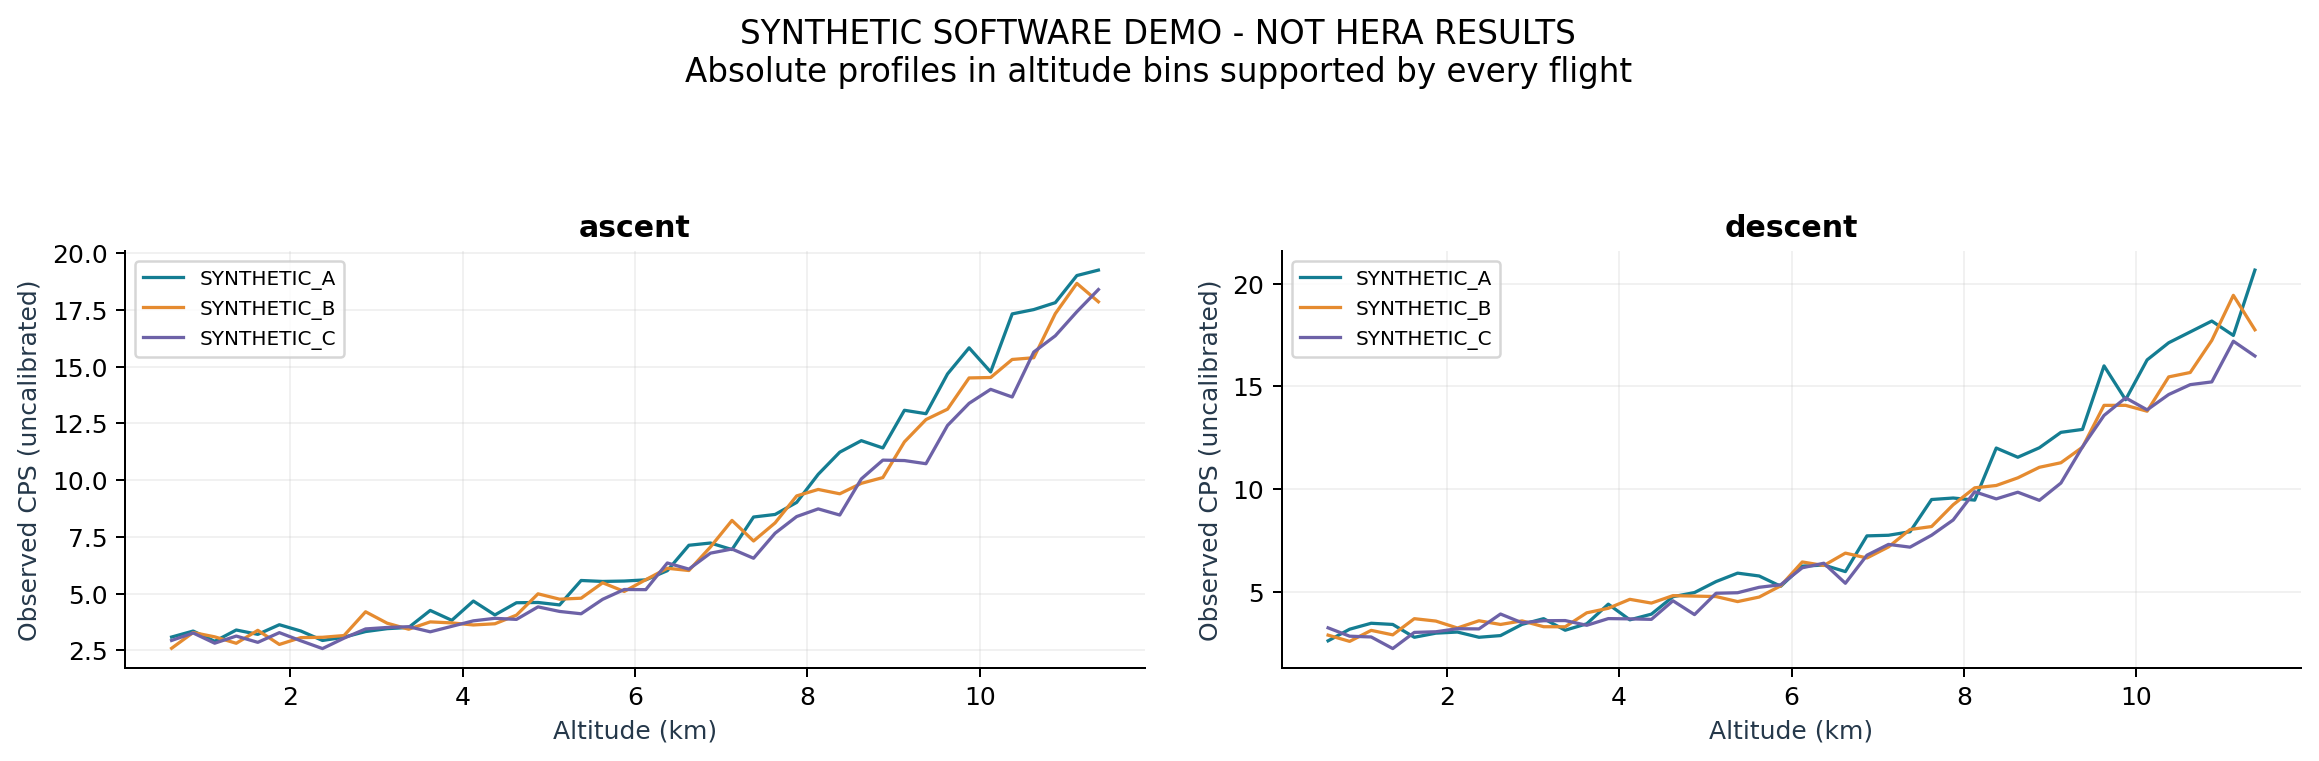

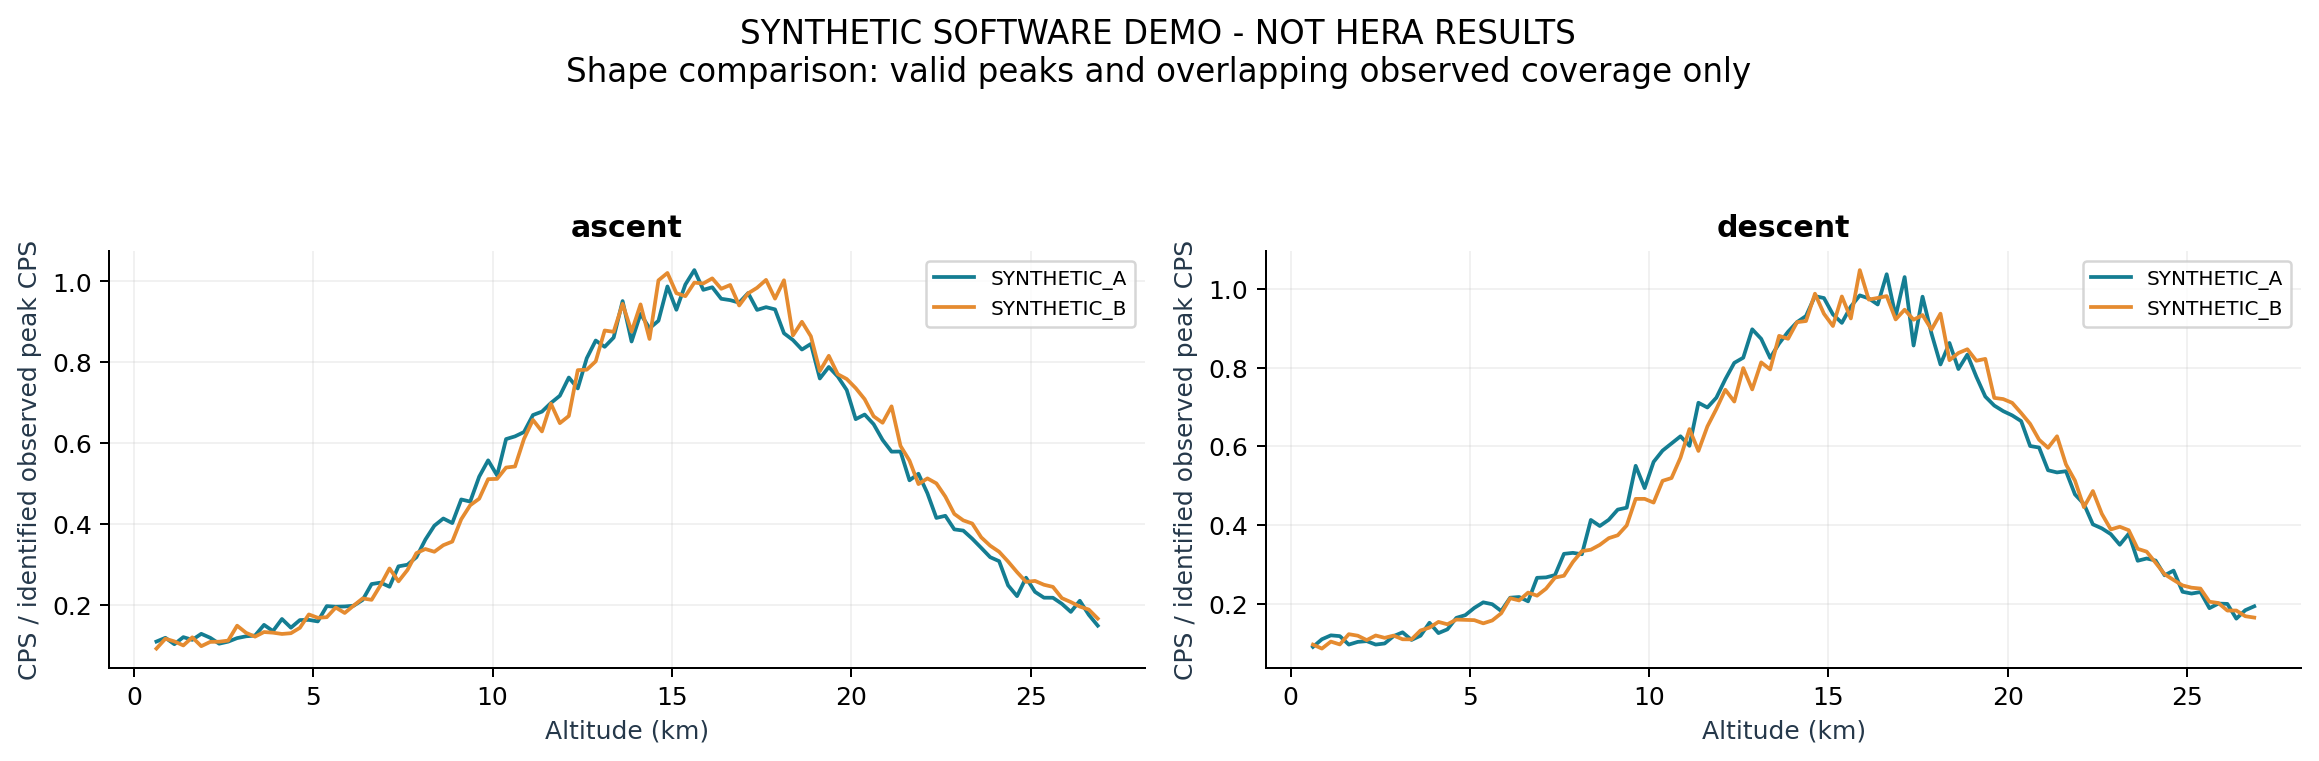

,mean,std
feature_group,,
altitude_pressure_density,8.862188,3.333278
magnetic,-0.001922,0.004031
motion,0.015294,0.021034
position,0.000000,0.000000
temperature,1.816052,0.890960


In [11]:
display(Image(filename=str(RESULTS / 'figures/common_coverage_overlay.png'), width=1100))
display(Image(filename=str(RESULTS / 'figures/normalized_shapes.png'), width=1100))
importance = pd.read_csv(RESULTS / 'cv_metrics/grouped_circular_importance.csv')
display(importance.groupby('feature_group').delta_rmse_cps.agg(['mean', 'std']))

## 8. Save an all-data model only for future flights

The supplied `results/synthetic_final/model.json` is a synthetic-only refit. Its training groups are all three fixtures, so it has no independent test score. The honest performance estimate is the outer CV analysis above.

For real data, the same `fit_final` function will run grouped tuning on all supplied flights and refit the predeclared tuned-engineered variant with seed 42. It does not choose the best outer-test seed.

In [13]:
from pfotzer_xgb.experiments import fit_final

REFIT_ALL_DATA = False
if REFIT_ALL_DATA:
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    model_folder = PROJECT_ROOT / 'results' / f'{MODE}_final_{stamp}'
    fit_final(DATA_PATH, model_folder, CONFIG, METADATA_PATH, seed=42)
    print('Saved final refit:', model_folder.name)
else:
    print('Refit disabled. Included synthetic refit is available under results/synthetic_final.')

Refit disabled. Included synthetic refit is available under results/synthetic_final.


## 9. Interpret the outcome honestly

Read `results/synthetic_demo/REPORT.md` for the complete example. In this example, tuning did not improve mean held-out RMSE over the baseline; that outcome is retained. It is not a finding about real HERA data.

The next empirical step is to supply paired CosmicWatch and CLUE files for **March 28, 2026; October 4, 2025; and June 1, 2025**, then verify their clocks and exposure conventions. More independent flights will strengthen the study. See the data checklist, experiment protocol and supervisor status report in `docs/`.

Before claiming a physical maximum, confirm both-side altitude coverage, detector response, meaningful prominence and processing stability. An honest unresolved result is an acceptable scientific outcome.